# Question 4: The Plot-Twist Generator

Can a small neural language model write a coherent, interesting story? We train a **Vanilla RNN** and an **LSTM** language model on a subset of **TinyStories**, compare decoding strategies (greedy, temperature, top-k), run a Plot-Twist Challenge, and evaluate with perplexity, Distinct-n, repetition rate, length statistics and blinded human ratings.

**Notebook outline**
1. Setup & reproducibility
2. Part 1 – Dataset preparation
3. Part 2 – Models and training
4. Part 3 – Decoding strategies
5. Part 4 – Plot-Twist Challenge
6. Part 5 – Quantitative + human evaluation
7. Part 6 – Final analysis
8. Saving artefacts for submission

## 0. Setup & reproducibility

In [2]:
import os, re, json, time, random, math, collections, textwrap, shutil, glob
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
print("device:", device, "| torch", torch.__version__, "| seed", SEED)

device: cuda | torch 2.11.0+cu130 | seed 42


## Part 1 — Dataset Preparation and Next-Token Prediction

**Subset used (documented):** 20,000 training stories, 1,000 validation stories, 1,000 test stories.
The splits are made **at story level before any sequence is built**. Training stories are sampled from TinyStories' `train` split; validation and test stories are sampled (disjoint) from its `validation` split.

**Tokenisation:** lower-casing + a regex word-level tokenizer (words, contractions, and `. , ! ? ; : "` as separate tokens). Both models share exactly the same tokenizer and vocabulary.

In [3]:
N_TRAIN, N_VAL, N_TEST = 20_000, 1_000, 1_000

ds = load_dataset("roneneldan/TinyStories")
rng = random.Random(SEED)


vt_idx = rng.sample(range(len(ds["validation"])), (N_VAL + N_TEST) * 2)
pool = ds["validation"].select(vt_idx)["text"]
seen, uniq = set(), []
for t in pool:
    if t not in seen:
        seen.add(t); uniq.append(t)
val_texts  = uniq[:N_VAL]
test_texts = uniq[N_VAL:N_VAL + N_TEST]
held_out = set(val_texts) | set(test_texts)


cand_idx = rng.sample(range(len(ds["train"])), N_TRAIN + 5000)
cand = ds["train"].select(cand_idx)["text"]
train_texts, seen_tr = [], set()
for t in cand:
    if t in held_out or t in seen_tr:
        continue
    seen_tr.add(t); train_texts.append(t)
    if len(train_texts) == N_TRAIN:
        break


assert len(train_texts) == N_TRAIN and len(val_texts) == N_VAL and len(test_texts) == N_TEST
assert not (set(train_texts) & set(val_texts)) and not (set(train_texts) & set(test_texts)) and not (set(val_texts) & set(test_texts))
print(len(train_texts), len(val_texts), len(test_texts))
print(train_texts[0][:300])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

20000 1000 1000
Once upon a time, there was a little boy named Timmy. Timmy loved playing with his toys, especially his toy cars. One day, Timmy's favorite toy car broke. He tried to fix it, but it was too fragile.

Timmy's dad came into the room and asked, "What happened, Timmy?"

"My toy car broke," Timmy said sa


In [4]:
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[.,!?;:\"]")

def clean(t):
    t = t.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"')
    return t.lower().strip()

def tokenize(t):
    return TOKEN_RE.findall(clean(t))

MAX_STORY_TOKENS = 100
def truncate_story(toks, max_len=MAX_STORY_TOKENS):
    if len(toks) <= max_len:
        return toks
    cut = toks[:max_len]
    ends = [i for i, w in enumerate(cut) if w in {".", "!", "?"}]
    return cut[: ends[-1] + 1] if ends and ends[-1] > 20 else cut

train_tok = [truncate_story(tokenize(t)) for t in train_texts]
val_tok   = [truncate_story(tokenize(t)) for t in val_texts]
test_tok  = [truncate_story(tokenize(t)) for t in test_texts]
train_tok = [s for s in train_tok if len(s) >= 10]
val_tok   = [s for s in val_tok   if len(s) >= 10]
test_tok  = [s for s in test_tok  if len(s) >= 10]
print("stories after filtering:", len(train_tok), len(val_tok), len(test_tok))
print("mean tokens/story (train):", np.mean([len(s) for s in train_tok]).round(1))

stories after filtering: 19999 1000 1000
mean tokens/story (train): 93.9


In [5]:
PAD, UNK, BOS, EOS = 0, 1, 2, 3
SPECIALS = ["<pad>", "<unk>", "<bos>", "<eos>"]
MIN_FREQ, MAX_VOCAB = 5, 8000

counter = collections.Counter(w for s in train_tok for w in s)
itos = SPECIALS + [w for w, c in counter.most_common(MAX_VOCAB - len(SPECIALS)) if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)

def encode_tokens(toks): return [stoi.get(w, UNK) for w in toks]
def decode_ids(ids):
    words = [itos[i] for i in ids if i not in (PAD, BOS, EOS)]
    txt = " ".join(words)
    txt = re.sub(r" ([.,!?;:])", r"\1", txt)
    return txt

train_ids = [[BOS] + encode_tokens(s) + [EOS] for s in train_tok]
val_ids   = [[BOS] + encode_tokens(s) + [EOS] for s in val_tok]
test_ids  = [[BOS] + encode_tokens(s) + [EOS] for s in test_tok]

unk_rate = np.mean([i == UNK for s in train_ids for i in s])
print(f"vocab size = {V} | UNK rate in train = {unk_rate:.2%}")
print("example ids:", train_ids[0][:15])
print("decoded    :", decode_ids(train_ids[0])[:150])

vocab size = 4959 | UNK rate in train = 0.39%
example ids: [2, 23, 28, 7, 24, 5, 20, 10, 7, 29, 57, 42, 55, 4, 55]
decoded    : once upon a time, there was a little boy named timmy. timmy loved playing with his toys, especially his toy cars. one day, timmy's favorite toy car br


In [6]:
class StoryDS(Dataset):
    def __init__(self, seqs): self.seqs = seqs
    def __len__(self): return len(self.seqs)
    def __getitem__(self, i): return self.seqs[i]

def collate(batch):
    L = max(len(b) for b in batch)
    arr = torch.full((len(batch), L), PAD, dtype=torch.long)
    for i, b in enumerate(batch): arr[i, :len(b)] = torch.tensor(b)
    return arr[:, :-1], arr[:, 1:]

BATCH = 64
train_dl = DataLoader(StoryDS(train_ids), batch_size=BATCH, shuffle=True,  collate_fn=collate)
val_dl   = DataLoader(StoryDS(val_ids),   batch_size=BATCH, shuffle=False, collate_fn=collate)
test_dl  = DataLoader(StoryDS(test_ids),  batch_size=BATCH, shuffle=False, collate_fn=collate)
x, y = next(iter(train_dl)); print(x.shape, y.shape)

torch.Size([64, 101]) torch.Size([64, 101])


**Why story boundaries must be preserved.** Each story is its own sequence wrapped in `<bos> … <eos>`. If stories were concatenated into one long stream, the model would learn to predict the first word of a story from the last words of an unrelated story (a meaningless dependency), could not learn when to *end* a story, and overlapping windows from the same story could leak into different splits. Splitting at story level before building sequences avoids this leakage.

**How padding is handled.** Stories in a batch are right-padded with `<pad>` to the longest story. Because padding is on the right, it can never influence earlier positions of a (left-to-right) RNN. The loss uses `ignore_index=PAD`, so padded target positions contribute nothing to the loss, the gradient, or perplexity.

**Note on truncation:** stories are cut at the last sentence end within 100 tokens (a compute limitation). The model therefore learns to produce short stories (~100 tokens).

## Part 2 — Two Neural Language Models
* **Model A:** Embedding → Vanilla RNN (tanh) → Linear → vocabulary logits
* **Model B:** Embedding → LSTM → Linear → vocabulary logits

Identical vocabulary, embedding dim (256), hidden dim (512), 1 layer, dropout (0.3), optimizer (Adam, lr 1e-3), gradient clipping (1.0), batch size (64), epochs (≤10, early stopping on validation loss, patience 2) and seed. The only unavoidable difference is the recurrent cell (and therefore the parameter count: an LSTM has 4× the recurrent weights).

In [7]:
class LM(nn.Module):
    def __init__(self, kind, V, E=256, H=512, layers=1, drop=0.3):
        super().__init__()
        self.kind = kind
        self.emb = nn.Embedding(V, E, padding_idx=PAD)
        self.drop = nn.Dropout(drop)
        if kind == "rnn":
            self.rnn = nn.RNN(E, H, layers, batch_first=True, nonlinearity="tanh")
        else:
            self.rnn = nn.LSTM(E, H, layers, batch_first=True)
        self.fc = nn.Linear(H, V)
    def forward(self, x, h=None):
        o, h = self.rnn(self.drop(self.emb(x)), h)
        return self.fc(self.drop(o)), h

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); tot, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits, _ = model(x)
        tot += F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), ignore_index=PAD, reduction="sum").item()
        n += (y != PAD).sum().item()
    return tot / n

def train_model(kind, epochs=10, lr=1e-3, patience=2, clip=1.0):
    set_seed(SEED)
    model = LM(kind, V).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": []}
    best, best_state, bad = float("inf"), None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            logits, _ = model(x)
            loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), ignore_index=PAD)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            k = (y != PAD).sum().item(); tot += loss.item() * k; n += k
        tr, va = tot / n, evaluate(model, val_dl)
        hist["train_loss"].append(tr); hist["val_loss"].append(va)
        print(f"[{kind}] epoch {ep:2d} | train loss {tr:.4f} | val loss {va:.4f} | val ppl {math.exp(va):.2f}")
        if va < best - 1e-4:
            best, bad = va, 0
            best_state = {k_: v.detach().clone() for k_, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: print("early stopping"); break
    secs = time.time() - t0
    model.load_state_dict(best_state)
    return model, hist, secs

models, hists, times = {}, {}, {}
for kind in ["rnn", "lstm"]:
    models[kind], hists[kind], times[kind] = train_model(kind)

[rnn] epoch  1 | train loss 3.9683 | val loss 3.2680 | val ppl 26.26
[rnn] epoch  2 | train loss 3.2793 | val loss 3.0336 | val ppl 20.77
[rnn] epoch  3 | train loss 3.1150 | val loss 2.9323 | val ppl 18.77
[rnn] epoch  4 | train loss 3.0246 | val loss 2.8697 | val ppl 17.63
[rnn] epoch  5 | train loss 2.9588 | val loss 2.8209 | val ppl 16.79
[rnn] epoch  6 | train loss 2.9108 | val loss 2.7861 | val ppl 16.22
[rnn] epoch  7 | train loss 2.8767 | val loss 2.7634 | val ppl 15.85
[rnn] epoch  8 | train loss 2.8488 | val loss 2.7471 | val ppl 15.60
[rnn] epoch  9 | train loss 2.8335 | val loss 2.7303 | val ppl 15.34
[rnn] epoch 10 | train loss 2.8027 | val loss 2.7239 | val ppl 15.24
[lstm] epoch  1 | train loss 4.1776 | val loss 3.3986 | val ppl 29.92
[lstm] epoch  2 | train loss 3.3340 | val loss 3.0646 | val ppl 21.43
[lstm] epoch  3 | train loss 3.0923 | val loss 2.8874 | val ppl 17.95
[lstm] epoch  4 | train loss 2.9414 | val loss 2.7738 | val ppl 16.02
[lstm] epoch  5 | train loss 2

,Model,Parameters,Train time (s),Epochs run,Val loss,Val PPL,Test loss,Test PPL
0,Vanilla RNN,4207711,128.0,10,2.7239,15.24,2.7171,15.14
1,LSTM,5390431,184.6,10,2.4819,11.96,2.4752,11.88


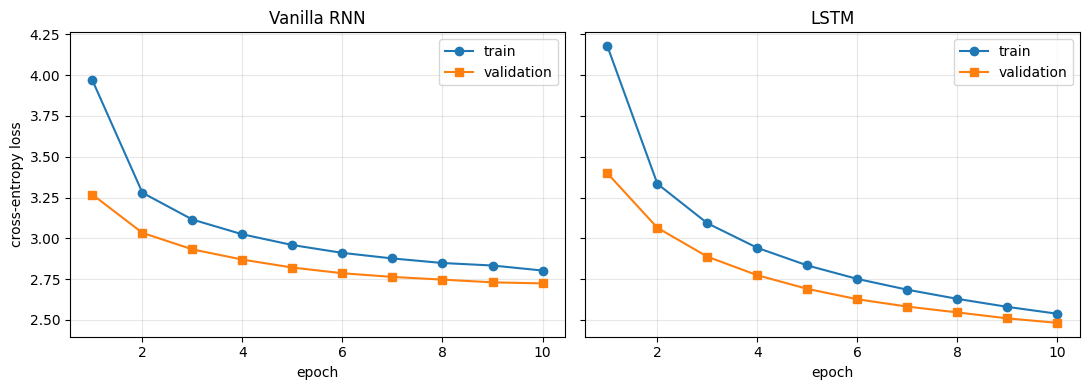

In [8]:
summary = []
for kind, name in [("rnn", "Vanilla RNN"), ("lstm", "LSTM")]:
    m = models[kind]
    v, t = evaluate(m, val_dl), evaluate(m, test_dl)
    summary.append({"Model": name, "Parameters": count_params(m), "Train time (s)": round(times[kind], 1),
                    "Epochs run": len(hists[kind]["val_loss"]),
                    "Val loss": round(v, 4), "Val PPL": round(math.exp(v), 2),
                    "Test loss": round(t, 4), "Test PPL": round(math.exp(t), 2)})
summary_df = pd.DataFrame(summary); display(summary_df)
summary_df.to_csv(f"{OUT}/lm_summary.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (kind, name) in zip(ax, [("rnn", "Vanilla RNN"), ("lstm", "LSTM")]):
    ep = range(1, len(hists[kind]["train_loss"]) + 1)
    a.plot(ep, hists[kind]["train_loss"], "o-", label="train"); a.plot(ep, hists[kind]["val_loss"], "s-", label="validation")
    a.set_title(name); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("cross-entropy loss")
plt.tight_layout(); plt.savefig(f"{OUT}/loss_curves.png", dpi=150); plt.show()

## Part 3 — Make the Stories Come Alive (decoding strategies)
Implemented strategies (all with incremental hidden-state decoding):
1. **Greedy** – argmax at each step
2. **Temperature sampling** – T ∈ {0.5, 0.8, 1.2}
3. **Top-k sampling** – k ∈ {10, 40} (temperature 1.0)

`<pad>` and `<bos>` are never generated. Generation stops at `<eos>` or after `max_new` tokens.

In [9]:

@torch.no_grad()
def generate(model, prompt, strategy="greedy", temperature=1.0, k=None, max_new=120, seed=None):
    model.eval()
    if seed is not None: torch.manual_seed(seed)
    ids = [BOS] + encode_tokens(tokenize(prompt))
    logits, h = model(torch.tensor([ids], device=device))
    logits = logits[0, -1]
    out, ended = [], False
    for _ in range(max_new):
        l = logits.clone(); l[PAD] = -float("inf"); l[BOS] = -float("inf")
        if strategy == "greedy":
            nid = int(l.argmax())
        else:
            l = l / temperature
            if strategy == "topk":
                kth = torch.topk(l, k).values[-1]; l[l < kth] = -float("inf")
            nid = int(torch.multinomial(F.softmax(l, -1), 1))
        if nid == EOS: ended = True; break
        out.append(nid)
        logits, h = model(torch.tensor([[nid]], device=device), h); logits = logits[0, -1]
    return out, ended

CONFIGS = {
    "greedy":      dict(strategy="greedy"),
    "temp0.5":     dict(strategy="temp", temperature=0.5),
    "temp0.8":     dict(strategy="temp", temperature=0.8),
    "temp1.2":     dict(strategy="temp", temperature=1.2),
    "topk10":      dict(strategy="topk", k=10, temperature=1.0),
    "topk40":      dict(strategy="topk", k=40, temperature=1.0),
}
MODEL_NAMES = {"rnn": "Vanilla RNN", "lstm": "LSTM"}

PROMPTS3 = {
    "mystery":              "One night, Mia heard a strange noise coming from the attic. She took a torch and slowly climbed the stairs.",
    "surprising discovery": "Tom was digging in the garden when his spade hit something hard. It was a small old box.",
    "unusual character":    "There was a little dragon who was afraid of fire. Every day, the other animals laughed at him.",
    "problem to solve":     "The bridge to the village was broken, and the children could not get to school. Sam wanted to help.",
    "unexpected ending":    "Lily baked a big cake for her mother's birthday. She put it on the table and went to get a candle.",
}
for name, p in PROMPTS3.items():
    unk = [w for w in tokenize(p) if w not in stoi]
    print(f"{name:22s} out-of-vocabulary words: {unk}")

mystery                out-of-vocabulary words: ['torch']
surprising discovery   out-of-vocabulary words: []
unusual character      out-of-vocabulary words: []
problem to solve       out-of-vocabulary words: []
unexpected ending      out-of-vocabulary words: []


In [10]:
rows3 = []
for pname, ptxt in PROMPTS3.items():
    for cname, cfg in CONFIGS.items():
        for kind in ["rnn", "lstm"]:
            n_samples = 1 if cfg["strategy"] == "greedy" else 2
            for s in range(n_samples):
                ids, ended = generate(models[kind], ptxt, seed=SEED + s, **cfg)
                rows3.append(dict(prompt_name=pname, prompt=ptxt, config=cname, model=MODEL_NAMES[kind],
                                  sample=s, n_tokens=len(ids), ended=ended, text=decode_ids(ids)))
df3 = pd.DataFrame(rows3); df3.to_csv(f"{OUT}/part3_generations.csv", index=False)

for pname, g in df3.groupby("prompt_name", sort=False):
    print("=" * 100); print("PROMPT:", g.iloc[0].prompt)
    for _, r in g.iterrows():
        print(f"\n[{r.model} | {r.config} | sample {r['sample']}]")
        print(textwrap.fill(r.text, 100))

PROMPT: One night, Mia heard a strange noise coming from the attic. She took a torch and slowly climbed the stairs.

[Vanilla RNN | greedy | sample 0]


[LSTM | greedy | sample 0]
she saw a big, scary monster! she was so excited that she ran to the tree and started to climb the
tree. she was so happy and excited. she ran to the tree and started to climb the tree. she was so
happy and excited. she ran to the tree and started to climb the tree.

[Vanilla RNN | temp0.5 | sample 0]
she looked up and saw a little girl. she was scared and didn't know what to do. she asked her mom, "
mommy, can i play with you? " lily asked. " i want to play with me. i have a surprise for you. "
jack smiled and said, " yes, i want to play with you.

[Vanilla RNN | temp0.5 | sample 1]
she saw a big, yellow bird. she was so excited and started to cry.

[LSTM | temp0.5 | sample 0]
she looked around and saw a big box with lots of leaves. she picked it up and looked inside. she
looked around and saw a big, shiny r

### Part 3 – Analysis
Evidence: `part3_generations.csv` (5 prompts × 6 settings × 2 models, 2 samples per sampling setting) and the 100-prompt metrics in Part 5a.

**Do greedy / low-temperature outputs repeat?** Yes, greedy decoding loops badly. The Vanilla RNN's greedy continuation of the bridge prompt is "he asked his mom if he could go to the park." repeated ten times. The LSTM's greedy continuation of the mystery prompt cycles through "she ran to the tree and started to climb the tree. she was so happy and excited." Over 100 prompts, greedy decoding has a repetition rate of 0.374 (RNN) and 0.340 (LSTM) and a Distinct-2 of only 0.032 and 0.089. 70% of the RNN's greedy outputs hit the 120-token limit without `<eos>`. For the mystery prompt the RNN's greedy output was empty, because it emitted `<eos>` immediately. T = 0.5 reduces looping (repetition 0.048 / 0.071) but the text stays generic and keeps reusing phrases ("it was a big, yellow car … it was very big, and it was very cold").

**Does T = 1.2 become incoherent?** Yes. T = 1.2 has the highest Distinct-2 (0.672 RNN, 0.677 LSTM) and almost no repetition (≤ 0.003), but grammar and meaning collapse. Examples: "she waved to the `<unk>` salon, then eyes and fell in the water where it was beautiful bright" (RNN, mystery) and "what me does surrender they do these?" (LSTM). The `<unk>` rate also peaks at 0.39 / 0.43 per 100 tokens. T = 0.8 is the best of the pure-temperature settings, with repetition 0.016 / 0.018 and Distinct-2 ≈ 0.40, though its stories often drift off-topic.

**Is top-k a compromise?** Partly. k = 10 gives Distinct-2 ≈ 0.355 for both models with low repetition (0.011 / 0.025) and few `<unk>` (0.05 / 0.10). k = 40 is more diverse than T = 0.8 (Distinct-2 0.431 / 0.447, repetition 0.010 / 0.012) without the breakdown seen at T = 1.2. But k is applied at T = 1.0, so the head of the distribution is not sharpened. k = 40 still produces drift ("the rain was very happy") and a higher `<unk>` rate (0.20 / 0.33) than T = 0.8 (0.11 / 0.11). So top-k is a useful compromise, not a strict improvement.

**RNN vs LSTM under the same decoding.** The LSTM's outputs have a stable length (mean ≈ 82 tokens, 0–1% hitting the limit). The RNN either stops after one or two sentences ("he saw a big, yellow bird. the bird was so excited to catch his friends.") or runs on without ending (21–25% at sampled settings, 70% greedy). Both models mostly ignore the prompt's details: the dragon prompt turns into a little fish or boy, and the bridge prompt turns into "he went to the store".

**Caveat on seeds.** Part 3 samples use fixed seeds (42 and 43), so the same random draws are reused across prompts. This likely explains why several outputs open identically ("she waved to the `<unk>` and tried to …"). That is a seeding artefact, not independent evidence.

## Part 4 — The Plot-Twist Challenge
Five openings designed to lead to a surprising development (worded with simple vocabulary so that most words exist in the TinyStories-based vocabulary; out-of-vocabulary words are reported below). Each opening is continued with **both models** and **two decoding strategies** (temperature 0.8 and top-k = 10). Generated text is *not* edited.

In [11]:
TWIST_PROMPTS = {
    "exam":    "A girl opened her test paper and saw something strange. The paper had the answers to tomorrow's questions.",
    "robot":   "An old robot sat alone in the garden. One day, it got a message from its future self.",
    "crime":   "The detective was sitting in his office. He was looking at a case of a crime that had not happened yet.",
    "village": "The sun rose over the little village. When everyone woke up, nobody could remember what happened yesterday.",
    "letter":  "A boy found a letter in the mail. It was written to him by someone one hundred years in the future.",
}
for k_, p in TWIST_PROMPTS.items():
    print(f"{k_:8s} OOV words: {[w for w in tokenize(p) if w not in stoi]}")

TWIST_CFGS = {"temp0.8": CONFIGS["temp0.8"], "topk10": CONFIGS["topk10"]}
twist_rows = []
for pname, ptxt in TWIST_PROMPTS.items():
    for cname, cfg in TWIST_CFGS.items():
        for kind in ["rnn", "lstm"]:
            ids, ended = generate(models[kind], ptxt, seed=SEED, **cfg)
            twist_rows.append(dict(opening=pname, prompt=ptxt, config=cname, model=MODEL_NAMES[kind],
                                   n_tokens=len(ids), ended=ended, text=decode_ids(ids)))
twist_df = pd.DataFrame(twist_rows)

for pname, g in twist_df.groupby("opening", sort=False):
    print("=" * 100); print("OPENING (human-written):", g.iloc[0].prompt)
    for _, r in g.iterrows():
        print(f"\n--- MODEL-GENERATED [{r.model} | {r.config}] ---")
        print(textwrap.fill(r.text, 100))

exam     OOV words: ["tomorrow's"]
robot    OOV words: ['self']
crime    OOV words: ['detective', 'crime']
village  OOV words: []
letter   OOV words: ['hundred']
OPENING (human-written): A girl opened her test paper and saw something strange. The paper had the answers to tomorrow's questions.

--- MODEL-GENERATED [Vanilla RNN | temp0.8] ---
she waved to the <unk> and tried to catch it too. luckily, jane, the raccoon looked very hard and
the boat was open. the sheep was very happy to see something and they were both. the dentist was so
grateful!

--- MODEL-GENERATED [LSTM | temp0.8] ---
she waved to the <unk> and tried to catch it, but it was too difficult. she looked around and saw
something shiny in the middle of her room. she asked her mom, " why is the car? " she asked. " it's
a brush, " replied the fairy. " oh no! my wand is not allowed! " so the little girl screamed. her
mom smiled and said, " it's a delicious surprise!

--- MODEL-GENERATED [Vanilla RNN | topk10] ---
she looked up

In [12]:
eval_sheet = twist_df[["opening", "config", "model", "text"]].copy()
for c in ["connected_to_prompt", "meaningful_twist", "consistent_details", "no_repetition_or_abrupt_jumps", "comment"]:
    eval_sheet[c] = ""
eval_sheet.to_csv(f"{OUT}/plot_twist_manual_eval.csv", index=False)
print("Saved outputs/plot_twist_manual_eval.csv - fill the 4 criteria columns (1 = yes, 0 = no) and add comments.")

Saved outputs/plot_twist_manual_eval.csv - fill the 4 criteria columns (1 = yes, 0 = no) and add comments.


In [ ]:
import pandas as pd

OUT = "outputs"
df = pd.read_csv(f"{OUT}/plot_twist_manual_eval.csv")
assert len(df) == 20

df["connected_to_prompt"]             = [0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0]
df["meaningful_twist"]                = [0]*20
df["consistent_details"]              = [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1]
df["no_repetition_or_abrupt_jumps"]   = [0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0]
df["comment"] = [
 "ignores test paper; random raccoon/boat/dentist; <unk>",
 "same <unk> opener; fairy and wand appear from nowhere",
 "new boy and voice appear; unrelated to paper",
 "echoes 'something strange'; no twist; repeats 'looked around'",
 "ignores robot and message; he/she switch",
 "deer/fish/lion drift; 'little girl' repeated",
 "one clean sentence but ignores prompt; same text as letter topk10 RNN",
 "girl and house, not robot; 'excited' loops",
 "names switch (tom, sam, jack); <unk>; dentist again",
 "phone becomes a monkey; no crime story",
 "four names (lily, ben, sam, jack); long drift",
 "man and john appear; no crime or detective link",
 "store, blanket, dentist; nothing about forgetting",
 "voice whisper is mildly mysterious but unrelated; lights singing",
 "store, forest, bunny; no link to village",
 "mentions people and sun (weak link); 'sun got home' is meaningless",
 "consistent 'he' but <unk> and 'ran after a tree'",
 "he becomes little girl; kitten, bird, car",
 "short and clean but ignores prompt; identical to robot topk10 RNN",
 "he/mom consistent; nothing about letter; broken quotes",
]
df.to_csv(f"{OUT}/plot_twist_manual_eval.csv", index=False)

crit = ["connected_to_prompt","meaningful_twist","consistent_details","no_repetition_or_abrupt_jumps"]
print(df.groupby("model")[crit].sum())
print(df.groupby("config")[crit].sum())

             connected_to_prompt  meaningful_twist  consistent_details  \
model                                                                    
LSTM                           2                 0                   2   
Vanilla RNN                    0                 0                   1   

             no_repetition_or_abrupt_jumps  
model                                       
LSTM                                     0  
Vanilla RNN                              2  
         connected_to_prompt  meaningful_twist  consistent_details  \
config                                                               
temp0.8                    0                 0                   1   
topk10                     2                 0                   2   

         no_repetition_or_abrupt_jumps  
config                                  
temp0.8                              0  
topk10                               2  


### Part 4 – Commentary (human-written, separate from model output)
I judged each of the 20 continuations on four yes/no criteria (table in the cell below; stored in `plot_twist_manual_eval.csv`). No generated text was edited.

| Criterion (count of "yes") | Vanilla RNN (of 10) | LSTM (of 10) |
|---|---|---|
| Connected to the opening | 0 | 2 |
| Meaningful development / twist | 0 | 0 |
| Consistent with earlier details | 1 | 2 |
| No heavy repetition / abrupt jumps | 2 | 0 |

By decoding setting (10 continuations each): temp 0.8 scored 0 / 0 / 1 / 0 on the four criteria, and top-k 10 scored 2 / 0 / 2 / 2.

**Successes (weak).**
* Exam, top-k 10, LSTM: "suddenly, the little girl noticed something strange in the grass." This echoes the opening's "something strange", but the story then drifts to a tree and a ball.
* Village, top-k 10, LSTM: it mentions "lots of people on the ground", a weak link to the village, but "when the sun got home" is meaningless.
* Letter, temp 0.8, RNN: it keeps "he" consistent throughout, but ignores the letter.

**Failures (the majority).**
* No continuation introduced a meaningful twist. The nearest thing is "he realized the phone was a messy monkey" (crime, LSTM), which is absurd rather than a development.
* Robot, temp 0.8, LSTM: the story drifts from deer to fish to girl to statue to lion.
* Crime, temp 0.8, RNN: the names switch between tom, sam and jack, and `<unk>` appears.
* Robot, temp 0.8, RNN: "he lived in a big hole, but she was too happy" switches pronoun.
* The two RNN outputs that passed the "no repetition / abrupt jumps" criterion are the same one-sentence text ("he was excited and asked her to come inside."), produced for both the robot and letter openings because the seed was identical. They are clean only because they ended after one sentence and ignore the prompt.

**RNN vs LSTM.** The LSTM connected to the prompt and kept details consistent slightly more often (2 vs 0 and 2 vs 1). It failed the repetition/abrupt-jump criterion in all 10 cases, against 2 of 10 for the RNN. That gap comes mostly from length: longer continuations give more room to drift. Several key opening words were out of vocabulary (`detective`, `crime`, `self`, `hundred`, `tomorrow's`), so the models could not follow the very plot elements that make these openings twists.

## Part 5 — Is the Better Language Model Also the Better Storyteller?
### 5a. Quantitative evaluation
* **Perplexity:** validation and test perplexity from Part 2 (same held-out test split).
* **Prompts:** first sentence of 100 held-out *test* stories (same prompts for both models and all settings).
* **Distinct-1 / Distinct-2:** number of unique unigrams / bigrams ÷ total unigrams / bigrams over all generated continuations of a (model, setting).
* **Repetition rate (our definition):** for each continuation, `1 − (unique trigrams / total trigrams)`; averaged over continuations. 0 = no repeated trigram; higher = more looping.
* **Length:** mean generated tokens; **premature termination** = `<eos>` within fewer than 10 generated tokens; **excessively long** = reached the 120-token limit without `<eos>`.

In [13]:
N_EVAL, GEN_MAX, MIN_OK = 100, 120, 10

def first_sentence(toks):
    for i, w in enumerate(toks):
        if w in {".", "!", "?"}: return toks[: i + 1]
    return toks[:15]

eval_prompts = [" ".join(first_sentence(s)) for s in test_tok[:N_EVAL]]

def ngrams(seq, n): return [tuple(seq[i:i + n]) for i in range(len(seq) - n + 1)]
def distinct_n(gens, n):
    allg = [g for seq in gens for g in ngrams(seq, n)]
    return len(set(allg)) / max(len(allg), 1)
def repetition_rate(seq, n=3):
    g = ngrams(seq, n)
    return 0.0 if not g else 1 - len(set(g)) / len(g)

metric_rows, store = [], {}
for kind in ["rnn", "lstm"]:
    for cname, cfg in CONFIGS.items():
        gens, endeds = [], []
        for i, p in enumerate(eval_prompts):
            ids, ended = generate(models[kind], p, seed=SEED + i, max_new=GEN_MAX, **cfg)
            gens.append(ids); endeds.append(ended)
        store[(kind, cname)] = (gens, endeds)
        lens = [len(g) for g in gens]
        metric_rows.append({
            "Model": MODEL_NAMES[kind], "Setting": cname,
            "Distinct-1": round(distinct_n(gens, 1), 3), "Distinct-2": round(distinct_n(gens, 2), 3),
            "Repetition rate": round(float(np.mean([repetition_rate(g) for g in gens])), 3),
            "Avg length": round(float(np.mean(lens)), 1),
            "Premature (<10 tok) %": round(100 * np.mean([(e and l < MIN_OK) for e, l in zip(endeds, lens)]), 1),
            "Too long (no EOS) %": round(100 * np.mean([not e for e in endeds]), 1),
            "<unk> per 100 tok": round(100 * sum(g.count(UNK) for g in gens) / max(sum(lens), 1), 2),
        })
metrics_df = pd.DataFrame(metric_rows)
metrics_df["Test PPL"] = metrics_df["Model"].map(dict(zip(summary_df["Model"], summary_df["Test PPL"])))
display(metrics_df); metrics_df.to_csv(f"{OUT}/generation_metrics.csv", index=False)

,Model,Setting,Distinct-1,Distinct-2,Repetition rate,Avg length,Premature (<10 tok) %,Too long (no EOS) %,<unk> per 100 tok,Test PPL
0,Vanilla RNN,greedy,0.013,0.032,0.374,113.4,0.0,70.0,0.00,15.14
1,Vanilla RNN,temp0.5,0.063,0.215,0.048,78.4,0.0,23.0,0.01,15.14
2,Vanilla RNN,temp0.8,0.110,0.396,0.016,70.9,0.0,21.0,0.11,15.14
3,Vanilla RNN,temp1.2,0.192,0.672,0.002,76.5,1.0,25.0,0.39,15.14
4,Vanilla RNN,topk10,0.092,0.355,0.011,66.1,0.0,17.0,0.05,15.14
5,Vanilla RNN,topk40,0.106,0.431,0.010,76.0,2.0,24.0,0.20,15.14
6,LSTM,greedy,0.031,0.089,0.340,82.4,0.0,0.0,0.00,11.88
7,LSTM,temp0.5,0.062,0.230,0.071,82.3,0.0,0.0,0.04,11.88
8,LSTM,temp0.8,0.112,0.403,0.018,81.3,0.0,0.0,0.11,11.88
9,LSTM,temp1.2,0.195,0.677,0.003,84.0,0.0,1.0,0.43,11.88


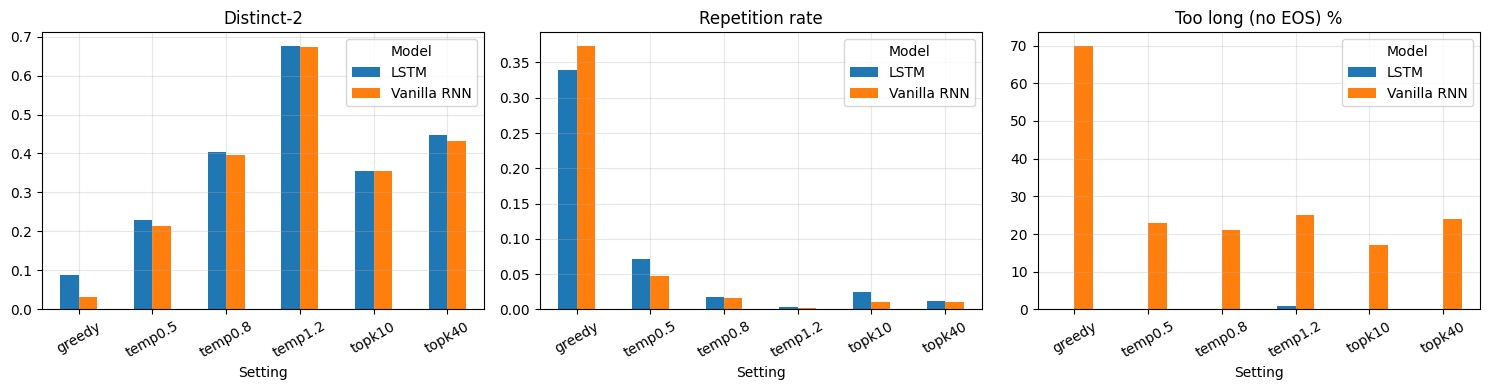

In [14]:

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["Distinct-2", "Repetition rate", "Too long (no EOS) %"]):
    piv = metrics_df.pivot(index="Setting", columns="Model", values=col).loc[list(CONFIGS)]
    piv.plot(kind="bar", ax=a, rot=30); a.set_title(col); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/generation_metrics.png", dpi=150); plt.show()

In [15]:
pool = twist_df.groupby("model", group_keys=False).apply(lambda g: g.sample(6, random_state=SEED)).sample(frac=1, random_state=SEED).reset_index(drop=True)
pool["sample_id"] = [f"S{i+1:02d}" for i in range(len(pool))]

blinded = pool[["sample_id", "prompt", "text"]].copy()
for c in ["coherence", "grammar", "relevance", "creativity"]: blinded[c] = ""
blinded.to_csv(f"{OUT}/blinded_samples.csv", index=False)
pool[["sample_id", "model", "config", "opening"]].to_csv(f"{OUT}/blinded_key_DO_NOT_SHARE.csv", index=False)
display(blinded[["sample_id", "text"]].head(3)); print("saved blinded_samples.csv and key")

/tmp/ipykernel_481/3565897738.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pool = twist_df.groupby("model", group_keys=False).apply(lambda g: g.sample(6, random_state=SEED)).sample(frac=1, random_state=SEED).reset_index(drop=True)


,sample_id,text
0,S01,he went to the store to buy a new place to exp...
1,S02,she waved to the <unk> and tried to catch it t...
2,S03,he waved to the <unk> and tried to pull it on ...


saved blinded_samples.csv and key


In [18]:
files = sorted(glob.glob(f"{OUT}/ratings_rater*.csv"))
if not files:
    print("No rating files found yet. Put ratings_rater1.csv, ratings_rater2.csv, ... in the outputs/ folder.")
else:
    key = pd.read_csv(f"{OUT}/blinded_key_DO_NOT_SHARE.csv")
    crit = ["coherence", "grammar", "relevance", "creativity"]
    allr = []
    for i, f in enumerate(files, 1):
        r = pd.read_csv(f)[["sample_id"] + crit]; r["rater"] = f"rater{i}"; allr.append(r)
    R = pd.concat(allr).merge(key, on="sample_id")
    print("Mean rating per model (all raters):");            display(R.groupby("model")[crit].mean().round(2))
    print("Mean rating per model and rater:");               display(R.groupby(["model", "rater"])[crit].mean().round(2))
    dis = R.groupby("sample_id")[crit].std().mean().round(2)
    print("Average per-sample std between raters (higher = more disagreement):"); display(dis)
    R.to_csv(f"{OUT}/human_eval_long.csv", index=False)

Mean rating per model (all raters):


,coherence,grammar,relevance,creativity
model,,,,
LSTM,2.33,3.33,1.83,2.17
Vanilla RNN,1.50,2.67,1.06,1.67


Mean rating per model and rater:


coherence  grammar  relevance  creativity
model       rater                                            
LSTM        rater1       2.00     3.00       1.50        2.00
            rater2       2.67     3.67       2.33        2.33
            rater3       2.33     3.33       1.67        2.17
Vanilla RNN rater1       1.33     2.33       1.00        1.33
            rater2       1.83     2.83       1.17        2.00
            rater3       1.33     2.83       1.00        1.67

Average per-sample std between raters (higher = more disagreement):


,0
coherence,0.34
grammar,0.34
relevance,0.29
creativity,0.29


### 5c. Does lower perplexity mean better storytelling?

| Model | Test PPL | Coherence | Grammar | Relevance | Creativity | Distinct-2 (T 0.8) | Repetition (T 0.8) | No-EOS % (T 0.8) |
|---|---|---|---|---|---|---|---|---|
| Vanilla RNN | 15.14 | 1.50 | 2.67 | 1.06 | 1.67 | 0.396 | 0.016 | 21% |
| LSTM | 11.88 | 2.33 | 3.33 | 1.83 | 2.17 | 0.403 | 0.018 | 0% |

**Between the two models, yes.** The LSTM has 21.5% lower test perplexity (11.88 vs 15.14). It also scored higher on all four human criteria, and this holds for each of the three raters individually. Rater 2 was the most lenient, but the model ranking was identical for all raters. Disagreement between raters was modest: the average per-sample standard deviation was 0.29–0.34 points on the 5-point scale. The LSTM also never ran on to the length limit at T = 0.8, while the RNN did in 21% of cases.

**But perplexity does not explain the quality of what is generated.**
* Perplexity is a property of the model alone. Within one model it is identical for all decoding settings, yet the LSTM's repetition rate is 0.340 under greedy decoding and 0.018 at T = 0.8, and its Distinct-2 goes from 0.089 to 0.677 at T = 1.2 (where the text is incoherent). Decoding choice changes story quality far more than perplexity does.
* Perplexity is measured with the true previous words (teacher forcing). Generation feeds the model its own output, so errors accumulate (exposure bias). It also does not check relevance to the prompt. Both models score very low on relevance (1.06 and 1.83 out of 5), and the LSTM's coherence is still only 2.33 out of 5.
* Diversity is not quality either. At T = 0.8 the two models have almost identical Distinct-2 (0.396 vs 0.403), but their human coherence differs by 0.83 points.

**Limits of this evidence.** This is two models, 12 rated samples (6 per model), 3 raters, one seed, and only two decoding settings (T = 0.8 and top-k 10). It shows a consistent pattern here, not a general rule that lower perplexity gives better stories.

## Part 6 — Final Analysis

**1. RNN vs LSTM in modelling sequential text.** The LSTM reached lower perplexity (validation 11.96 vs 15.24, test 11.88 vs 15.14) and lower training loss (2.54 vs 2.80 at epoch 10). It fell behind in epochs 1–2 and overtook the RNN from epoch 3. It costs more: 5.39M vs 4.21M parameters (+28%) and 184.6 s vs 128.0 s of training. The LSTM learned the length of a story, with a mean of about 82 generated tokens and almost no runaway outputs. The RNN often stops after a sentence or two or never ends (70% of greedy outputs). This is consistent with the gated cell state keeping longer-range information than the tanh RNN, though we did not test the mechanism directly. Neither model reliably tracks entities: names, pronouns and characters drift in both.

**2. Which model is more coherent and less repetitive?** The LSTM is more coherent (human coherence 2.33 vs 1.50) and finishes its stories. On repetition the picture is mixed. The LSTM loops slightly less under greedy decoding (0.340 vs 0.374) but slightly more at T = 0.5 (0.071 vs 0.048) and top-k 10 (0.025 vs 0.011), partly because its texts are longer.

**3. Effect of temperature.**

| T | Distinct-2 (RNN / LSTM) | Repetition (RNN / LSTM) | `<unk>` per 100 tok (RNN / LSTM) |
|---|---|---|---|
| 0.5 | 0.215 / 0.230 | 0.048 / 0.071 | 0.01 / 0.04 |
| 0.8 | 0.396 / 0.403 | 0.016 / 0.018 | 0.11 / 0.11 |
| 1.2 | 0.672 / 0.677 | 0.002 / 0.003 | 0.39 / 0.43 |

Raising T increases diversity and lowers repetition, but at 1.2 grammar breaks down, as the Part 3 samples show. Human ratings only cover T = 0.8 and top-k 10, so the grammar claim for T = 0.5 and 1.2 rests on reading the samples, not on rated data.

**4. Can higher diversity guarantee better stories?** No. T = 1.2 has the highest Distinct-2 but the least readable text. At T = 0.8 the two models have nearly identical Distinct-2 (0.396 vs 0.403) yet differ clearly in human coherence (1.50 vs 2.33).

**5. Does lower perplexity mean better storytelling in our experiments?** Across the two models, yes: the lower-perplexity LSTM was rated higher on all four criteria. Within a model, decoding matters more, and absolute quality is low for both (see 5c). With only two models, this is not evidence of a general rule.

**6. Most frequent failures and how to reduce them.**
* Ignoring or forgetting the prompt (relevance 1.06 / 1.83 out of 5). The dragon prompt becomes a fish or boy story; the bridge prompt becomes "went to the store".
* Entity drift: names switching between tom, sam, jack and lily, and he/she switches.
* Repetition loops under greedy decoding.
* Non-sequiturs and abrupt jumps ("the phone was a messy monkey").
* `<unk>` artefacts, including the recurring opener "waved to the `<unk>`", and out-of-vocabulary key words in the prompts.
* The RNN failing to terminate, or ending after one sentence.
* Incoherent text at high temperature.

Possible fixes: subword (BPE) tokenisation to remove `<unk>`, more data and training until validation loss stops improving, a repetition penalty or no-repeat n-gram blocking, nucleus sampling, an architecture with attention, training explicitly on prompt-to-continuation pairs, or a pretrained LM.

**7. Limitations.**
* Only 20,000 short stories (19,999 after filtering), truncated to about 100 tokens, so models learn very short stories.
* Word-level vocabulary of 4,959 words (cap 8,000, min frequency 5) with `<unk>`; several words in the challenge prompts are out of vocabulary.
* Small single-layer models trained for 10 epochs; validation loss was still falling and early stopping never triggered, so both are probably under-trained.
* A single seed (42), so there is no variance estimate.
* Part 3 and Part 4 samples reuse fixed seeds, so some outputs share openings.
* 100 evaluation prompts; only 12 human-rated samples and 3 raters, covering only T = 0.8 and top-k 10.
* The Part 4 yes/no labels are subjective.
* TinyStories' simple, repetitive style limits how creative any model trained on it can be.
* Perplexity is word-level, so it is not comparable with subword models.

## Saving artefacts for submission

In [17]:
for kind in ["rnn", "lstm"]:
    torch.save({"state_dict": models[kind].state_dict(), "kind": kind, "V": V, "E": 256, "H": 512, "layers": 1}, f"{OUT}/{kind}_lm.pt")
json.dump({"itos": itos, "special": {"pad": PAD, "unk": UNK, "bos": BOS, "eos": EOS},
           "tokenizer_regex": TOKEN_RE.pattern, "min_freq": MIN_FREQ, "max_vocab": MAX_VOCAB,
           "max_story_tokens": MAX_STORY_TOKENS}, open(f"{OUT}/vocab.json", "w"))
json.dump({"seed": SEED, "n_train": len(train_tok), "n_val": len(val_tok), "n_test": len(test_tok),
           "batch": BATCH, "lr": 1e-3, "clip": 1.0, "dropout": 0.3, "embedding_dim": 256, "hidden_dim": 512,
           "gen_configs": CONFIGS, "gen_max_tokens": GEN_MAX, "n_eval_prompts": N_EVAL,
           "twist_configs": list(TWIST_CFGS)}, open(f"{OUT}/settings.json", "w"), indent=2)

readme = """# Plot-Twist Generator (NLP Group Assignment 2, Q4)

## Setup
pip install torch datasets pandas numpy matplotlib

## Reproduce
1. Open `plot_twist_generator.ipynb` (GPU recommended, e.g. Colab) and run all cells top to bottom (seed = 42).
2. The notebook downloads TinyStories via Hugging Face (not included in this archive).
3. Outputs are written to `outputs/`: loss curves, generation metrics, generated stories, blinded human-eval files,
   checkpoints (`rnn_lm.pt`, `lstm_lm.pt`), `vocab.json`, `settings.json`.
4. To load a checkpoint: build `LM(kind, V)` from the notebook, then `load_state_dict(torch.load(path)["state_dict"])`.

## Data
20,000 train stories (random sample of TinyStories `train`), 1,000 val + 1,000 test stories (disjoint random samples of
TinyStories `validation`). Word-level tokenizer, vocabulary 8,000 (min freq 5), stories truncated to ~100 tokens.
"""
open(f"{OUT}/README.md", "w").write(readme)

shutil.make_archive("Q4_plot_twist_submission", "zip", OUT)
print("created Q4_plot_twist_submission.zip:", os.listdir(OUT))

created Q4_plot_twist_submission.zip: ['loss_curves.png', 'settings.json', 'lstm_lm.pt', 'README.md', 'blinded_key_DO_NOT_SHARE.csv', 'lm_summary.csv', 'blinded_samples.csv', 'generation_metrics.csv', 'part3_generations.csv', 'generation_metrics.png', 'plot_twist_manual_eval.csv', 'rnn_lm.pt', 'vocab.json']


In [20]:
twist_df.to_csv(f"{OUT}/part4_generations.csv", index=False)

settings = json.load(open(f"{OUT}/settings.json"))
settings["seeds"] = {"split_and_training": SEED, "part3_samples": [SEED, SEED + 1],
                     "part4_challenge": SEED, "part5_prompt_i": "SEED + i", "human_eval_sampling": SEED}
settings["human_eval"] = {"n_samples": 12, "n_raters": 3}
json.dump(settings, open(f"{OUT}/settings.json", "w"), indent=2)

nb = sorted(glob.glob("plot_twist_generator*.ipynb"))
if nb: shutil.copy(nb[0], f"{OUT}/plot_twist_generator.ipynb")
else:  print("Notebook not found on disk - download the .ipynb (with outputs) and add it to the zip manually.")

required = ["ratings_rater1.csv", "ratings_rater2.csv", "ratings_rater3.csv", "human_eval_long.csv",
            "plot_twist_manual_eval.csv", "blinded_samples.csv", "blinded_key_DO_NOT_SHARE.csv",
            "rnn_lm.pt", "lstm_lm.pt", "vocab.json", "loss_curves.png", "generation_metrics.csv", "README.md"]
missing = [f for f in required if not os.path.exists(f"{OUT}/{f}")]
print("MISSING:", missing if missing else "none")
shutil.make_archive("Q4_plot_twist_submission", "zip", OUT)
print(sorted(os.listdir(OUT)))

Notebook not found on disk - download the .ipynb (with outputs) and add it to the zip manually.
MISSING: none
['README.md', 'blinded_key_DO_NOT_SHARE.csv', 'blinded_samples.csv', 'generation_metrics.csv', 'generation_metrics.png', 'human_eval_long.csv', 'lm_summary.csv', 'loss_curves.png', 'lstm_lm.pt', 'part3_generations.csv', 'part4_generations.csv', 'plot_twist_manual_eval.csv', 'ratings_rater1.csv', 'ratings_rater2.csv', 'ratings_rater3.csv', 'rnn_lm.pt', 'settings.json', 'vocab.json']
